In [1]:
from glob import glob

import pandas as pd

data = glob("data/terna_load_**.csv")
df = pd.concat([pd.read_csv(d, index_col=0) for d in data])

area = "Italy"
df = df[df["Bidding Zone"] == area]
df = df.drop("Bidding Zone", axis=1)

df = df.rename(
    {
        "Date": "date",
        "Total Load [MW]": "total_load",
        "Forecast Total Load [MW]": "forecast_total_load",
    },
    axis=1,
)
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

# Treat the first duplicate as the pre-daylight savings timestamp
# First -> Summer (True); Second -> Winter (False)
is_summer = ~df.index.duplicated(keep="first")

df = df.tz_localize("Europe/Rome", ambiguous=is_summer)
df = df.tz_convert("UTC").sort_index()

df

,total_load,forecast_total_load
date,,
2018-12-31 23:00:00+00:00,24370.000,25009.000
2018-12-31 23:15:00+00:00,24202.000,24794.001
2018-12-31 23:30:00+00:00,24142.000,24580.000
2018-12-31 23:45:00+00:00,23969.000,24366.001
2019-01-01 00:00:00+00:00,23599.001,24143.000
...,...,...
2026-11-13 21:45:00+00:00,33250.999,33622.999
2026-11-13 22:00:00+00:00,32620.000,32902.001
2026-11-13 22:15:00+00:00,31911.000,32067.001


In [2]:
# Find gaps in index
diff = df.index.to_series().diff()
t = diff[diff > pd.Timedelta("15min")]
gaps = pd.DataFrame(
    {
        "start": t.index - t.values,
        "end": t.index,
        "missing": (t // pd.Timedelta("15min")).values - 1,
    }
)

print(gaps)

                      start                       end  missing
0 2019-10-26 23:45:00+00:00 2019-10-27 02:00:00+00:00        8
1 2023-12-31 22:45:00+00:00 2024-01-01 23:00:00+00:00       96
2 2026-01-13 22:45:00+00:00 2026-01-15 23:00:00+00:00      192


Note sui gap: 
- **2019-10-26 23:45:00+00:00 - 2019-10-27 02:00:00+00:00**: dovuto all'ora legale. Durante quest'anno, il timestamp duplicato è stato perso;
- **2023-12-31 22:45:00+00:00 - 2024-01-01 23:00:00+00:00**: il Capodanno del 2024 è assente dal dataset;
- **2026-01-13 22:45:00+00:00 - 2026-01-15 23:00:00+00:00**: 14-15 Gen sono completamente assenti dal dataset.

In [3]:
df = df.reindex(pd.date_range(df.iloc[0].name, df.iloc[-1].name, freq="15min"))

df

,total_load,forecast_total_load
2018-12-31 23:00:00+00:00,24370.000,25009.000
2018-12-31 23:15:00+00:00,24202.000,24794.001
2018-12-31 23:30:00+00:00,24142.000,24580.000
2018-12-31 23:45:00+00:00,23969.000,24366.001
2019-01-01 00:00:00+00:00,23599.001,24143.000
...,...,...
2026-11-13 21:45:00+00:00,33250.999,33622.999
2026-11-13 22:00:00+00:00,32620.000,32902.001
2026-11-13 22:15:00+00:00,31911.000,32067.001
2026-11-13 22:30:00+00:00,31163.999,31406.998


In [4]:
df["is_missing"] = df.isna().any(axis=1)

# Interpolate missing values
cols = ["total_load", "forecast_total_load"]

for i in range(len(gaps)):
    w = slice(gaps.iloc[i]["start"], gaps.iloc[i]["end"])
    df.loc[w, cols] = df.loc[w, cols].interpolate(method="time")

print(df.loc[w, cols + ["is_missing"]])

                             total_load  forecast_total_load  is_missing
2026-01-13 22:45:00+00:00  32986.001000         34226.000000       False
2026-01-13 23:00:00+00:00  32975.923275         34216.264254        True
2026-01-13 23:15:00+00:00  32965.845549         34206.528508        True
2026-01-13 23:30:00+00:00  32955.767824         34196.792762        True
2026-01-13 23:45:00+00:00  32945.690098         34187.057016        True
...                                 ...                  ...         ...
2026-01-15 22:00:00+00:00  31081.310902         32385.943984        True
2026-01-15 22:15:00+00:00  31071.233176         32376.208238        True
2026-01-15 22:30:00+00:00  31061.155451         32366.472492        True
2026-01-15 22:45:00+00:00  31051.077725         32356.736746        True
2026-01-15 23:00:00+00:00  31041.000000         32347.001000       False

[194 rows x 3 columns]


In [8]:
df.to_parquet("data/processed/terna_load.parquet")

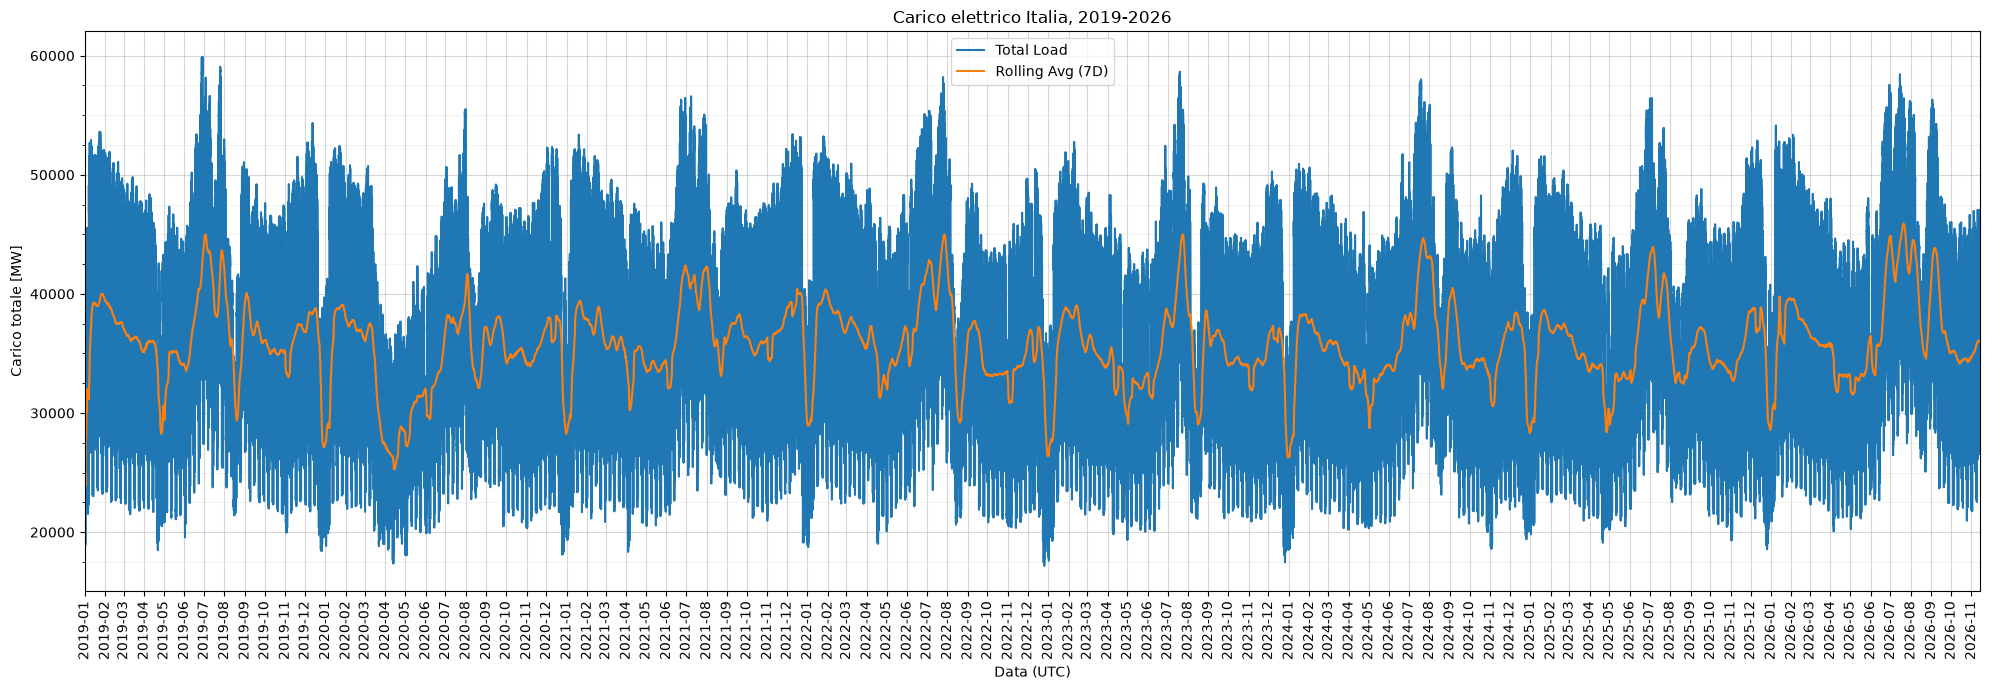

In [9]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(20, 7))

ax.plot(df.index, df["total_load"], label="Total Load")
ax.plot(
    df.index,
    df["total_load"].rolling("7D").mean(),
    linewidth=1.5,
    color="tab:orange",
    label="Rolling Avg (7D)",
)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_locator(mdates.MonthLocator())

ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.yaxis.set_minor_locator(plt.MultipleLocator(2500))

ax.tick_params(axis="x", rotation=90)

ax.grid(which="major", alpha=0.5)
ax.grid(which="minor", alpha=0.15)

ax.set_xlabel("Data (UTC)")
ax.set_ylabel("Carico totale [MW]")
ax.set_title("Carico elettrico Italia, 2019-2026")
ax.margins(x=0)
ax.legend(loc="upper center")

plt.tight_layout()
plt.show()

In [40]:
df["total_load"].sort_values().head(50)
df[(df["total_load"] == 0) | (df["forecast_total_load"] == 0)]
s = df["total_load"]
run_id = (s != s.shift()).cumsum()

idx = s.index.to_series()
runs = pd.DataFrame(
    {
        "valore": s.groupby(run_id).first(),
        "lunghezza": s.groupby(run_id).size(),
        "inizio": idx.groupby(run_id).first(),
        "fine": idx.groupby(run_id).last(),
    }
)

rep = runs[runs["lunghezza"] > 1]
print(rep["lunghezza"].value_counts().sort_index())
print(rep.sort_values("lunghezza", ascending=False).head(20))

lunghezza
2    74
Name: count, dtype: int64
               valore  lunghezza                    inizio  \
total_load                                                   
646         51530.000          2 2019-01-07 16:15:00+00:00   
3517        46726.000          2 2019-02-06 14:15:00+00:00   
3602        44889.000          2 2019-02-07 11:45:00+00:00   
4946        42457.000          2 2019-02-21 12:00:00+00:00   
14367       40913.000          2 2019-05-30 15:30:00+00:00   
18021       38144.000          2 2019-07-07 17:15:00+00:00   
24290       28403.000          2 2019-09-11 00:45:00+00:00   
24730       30892.999          2 2019-09-15 15:00:00+00:00   
42484       33835.000          2 2020-03-18 13:45:00+00:00   
42573       32947.000          2 2020-03-19 12:15:00+00:00   
55057       49195.000          2 2020-07-27 13:30:00+00:00   
55917       41849.001          2 2020-08-05 12:45:00+00:00   
57437       38577.000          2 2020-08-21 09:00:00+00:00   
63964       43145.000     

In [102]:
s = df["total_load"]
d = s.diff()

# Un salto di 2000 MW alle 7 di mattina è normale, alle 3 di notte no: normalizzo per ora locale
hour = s.index.tz_convert("Europe/Rome").hour
score = d.abs() / d.abs().groupby(hour).transform("median")

top = (
    pd.DataFrame(
        {
            "ora_locale": s.index.tz_convert("Europe/Rome"),
            "carico": s,
            "variazione": d,
            "score": score,
        }
    )
    .sort_values("score", ascending=False)
    .head(30)
).set_index("ora_locale")

print(top)

                              carico  variazione      score
ora_locale                                                 
2024-10-18 10:00:00+02:00  45403.999   -2857.001  13.735648
2024-03-24 03:00:00+01:00  21903.001    1568.002  13.517259
2025-04-14 18:30:00+02:00  42151.000    3202.001  12.174909
2025-03-23 03:00:00+01:00  22321.000    1359.000  11.715517
2022-06-05 15:00:00+02:00  33613.000    1983.000  10.777291
2022-06-23 15:15:00+02:00  51884.000   -1956.000  10.630550
2023-04-07 15:15:00+02:00  36353.001   -1933.000  10.505549
2022-05-01 13:30:00+02:00  24372.001   -2513.000   9.893701
2020-03-28 18:45:00+01:00  34066.000    2549.001   9.692019
2024-03-31 15:15:00+02:00  25207.000    1778.000   9.663149
2023-12-22 11:45:00+01:00  36868.999   -2038.000   9.479026
2025-03-23 02:00:00+01:00  21282.000   -1770.000   9.465215
2022-09-16 15:00:00+02:00  46749.000    1737.001   9.440325
2022-09-17 15:30:00+02:00  31633.999    1725.999   9.380531
2019-02-16 18:00:00+01:00  39628.999    

In [89]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error,
)

y = df["total_load"]
preds = {
    "Terna": df["forecast_total_load"],
    "ieri": y.shift(96),  # 96 campioni = 24 ore
    "settimana scorsa": y.shift(672),  # 672 campioni = 7 giorni
}

tab = pd.DataFrame({"y": y, **preds}).dropna()

res = pd.DataFrame(
    {
        name: {
            "RMSE": root_mean_squared_error(tab["y"], tab[name]),
            "MAE": mean_absolute_error(tab["y"], tab[name]),
            "MAPE %": 100 * mean_absolute_percentage_error(tab["y"], tab[name]),
            "bias": (tab[name] - tab["y"]).mean(),
        }
        for name in preds
    }
).T
print(res.round(2))
print("campioni confrontati:", len(tab))

                     RMSE      MAE  MAPE %    bias
Terna              980.33   741.78    2.10  217.81
ieri              5211.57  3324.26    9.46    0.53
settimana scorsa  3643.69  2282.56    6.52   -8.38
campioni confrontati: 275232


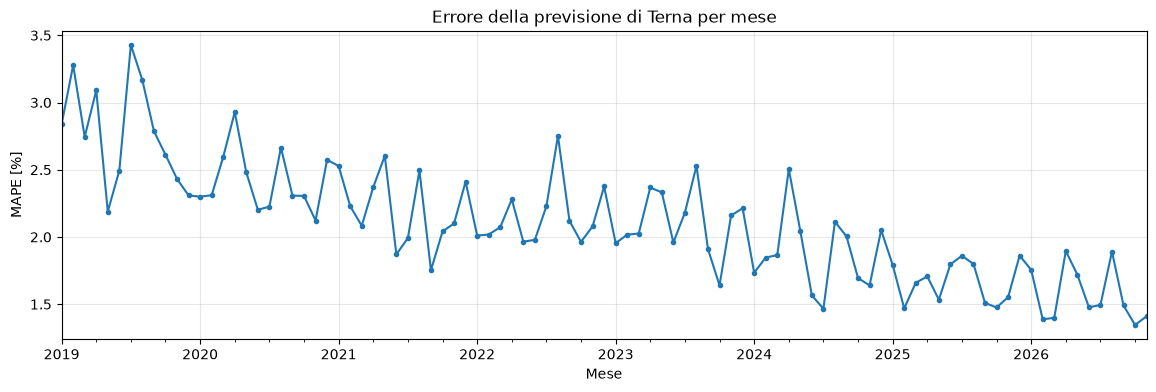

In [74]:
m = df[["total_load", "forecast_total_load"]].dropna()
mese = m.index.tz_convert("Europe/Rome").tz_localize(None).to_period("M")

mape_m = 100 * m.groupby(mese).apply(
    lambda g: mean_absolute_percentage_error(g["total_load"], g["forecast_total_load"])
)

ax = mape_m.plot(figsize=(14, 4), marker="o", markersize=3)
ax.set_ylabel("MAPE [%]")
ax.set_xlabel("Mese")
ax.set_title("Errore della previsione di Terna per mese")
ax.grid(alpha=0.3)